# Modèle de tarification dynamique — étude et entraînement

**Objectif** : proposer un **prix journalier** (en TND) pour une location, à partir de la catégorie du véhicule,
de l'agence, de la saison, du jour de départ, de la durée, du délai de réservation et du taux d'occupation.

**Démarche** :
1. charger l'historique synthétique et calculer les variables ;
2. explorer les données avec des graphiques ;
3. découper en trois jeux : entraînement (60 %), validation (20 %), test (20 %) ;
4. préparer les colonnes (`ColumnTransformer`) dans un `Pipeline` ;
5. entraîner 3 modèles : régression linéaire (référence), Random Forest, XGBoost ;
6. les comparer avec la **MAE** et le **R²** sur la validation, et choisir le meilleur ;
7. calculer l'**intervalle de prix** sur la validation ;
8. mesurer le modèle retenu **une seule fois** sur le test (MAE, R², couverture de l'intervalle) ;
9. calculer le **tableau d'occupation** et sauvegarder le modèle avec joblib (`artifacts/price_model_v1.joblib`).

Les fonctions utilisées viennent de `app/model_training.py` (entraînement, évaluation),
`app/model_artifacts.py` (sauvegarde) et `app/price_features.py` (variables) :
c'est **le même code** que celui qu'utilisera l'API pour réentraîner et prédire.

## 1. Préparer le notebook

Le notebook est dans `notebooks/`, mais notre code est dans `app/` (un dossier au-dessus).
On ajoute donc le dossier du service au chemin de recherche de Python (`sys.path`) pour pouvoir écrire
`from app.model_training import ...`.

On fixe aussi le style des graphiques : 3 couleurs toujours dans le même ordre
(bleu = Économique, orange = SUV, aqua = Luxe ; même ordre pour les saisons et les modèles).

In [1]:
import sys
from datetime import date
from pathlib import Path

service_dir = Path.cwd() if (Path.cwd() / "app").exists() else Path.cwd().parent
if str(service_dir) not in sys.path:
    sys.path.insert(0, str(service_dir))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from app import model_artifacts, model_training
from app.price_features import build_features, features_from_history
from app.rental_catalog import AGENCY_ID_BY_CODE, CATEGORIES, CATEGORY_ID_BY_CODE

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # bleu, orange, aqua
CATEGORY_ORDER = ["ECONOMIQUE", "SUV", "LUXE"]
SEASON_ORDER = ["BASSE", "MOYENNE", "HAUTE"]
AGENCY_ORDER = ["TUNIS", "SOUSSE"]
WEEKDAY_NAMES = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]

sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e0", "axes.edgecolor": "#c3c2b7"})
pd.set_option("display.precision", 3)
print("Dossier du service :", service_dir)

Dossier du service : C:\dev\location-voitures\services\ml-service


## 2. Charger les données

Le fichier `data/synthetic_reservations.csv` a été produit par `scripts/generate_rental_dataset.py`.
Ses colonnes ont le **même format que l'événement `ReservationCompleted`** (camelCase),
plus `occupancyRate` (taux d'occupation au moment de la réservation) et `dailyPrice` (le prix à prédire).

In [2]:
raw_reservations = pd.read_csv(model_training.DATASET_PATH)
print(f"{len(raw_reservations)} réservations, {raw_reservations.shape[1]} colonnes")
raw_reservations.head()

10000 réservations, 8 colonnes


,categoryId,agencyId,bookedAt,startDate,endDate,occupancyRate,dailyPrice,totalPrice
0,94236cd0-16fc-41e0-bfc2-c8b1d2c8b1fc,eb825ac4-855b-499b-b37a-b4c37bbd6b4e,2022-10-12T16:34:00Z,2023-01-31,2023-02-03,0.548,66.980,200.940
1,94236cd0-16fc-41e0-bfc2-c8b1d2c8b1fc,eb825ac4-855b-499b-b37a-b4c37bbd6b4e,2022-10-15T16:26:00Z,2023-01-04,2023-01-11,0.602,77.740,544.180
2,a6ec349d-0ff0-4cb1-bfb9-453dd8e2ee8c,1deb1dea-ab54-436d-8ed7-c3322f782c88,2022-10-17T14:11:00Z,2023-01-11,2023-01-27,0.377,84.460,1351.360
3,a6ec349d-0ff0-4cb1-bfb9-453dd8e2ee8c,eb825ac4-855b-499b-b37a-b4c37bbd6b4e,2022-10-23T13:54:00Z,2023-01-03,2023-01-08,0.690,134.452,672.260
4,94236cd0-16fc-41e0-bfc2-c8b1d2c8b1fc,eb825ac4-855b-499b-b37a-b4c37bbd6b4e,2022-10-25T12:27:00Z,2023-01-03,2023-01-06,0.679,79.893,239.679


### Des données brutes aux variables du modèle

`features_from_history()` calcule, pour chaque réservation :
- `category`, `agency` : code lisible à partir de l'UUID (via `rental_catalog.py`) ;
- `season` : à partir du mois de départ ;
- `start_weekday` : jour de la semaine du départ (0 = lundi … 6 = dimanche) ;
- `duration_days` = endDate − startDate ;
- `lead_time_days` = startDate − date de bookedAt (délai de réservation) ;
- `occupancy_rate` et la cible `daily_price`.

À la prédiction, l'API fera exactement le même calcul avec `build_features()` (et « aujourd'hui » comme date de réservation).

In [3]:
feature_table = features_from_history(raw_reservations)
feature_table.head()

,category,agency,season,start_weekday,duration_days,lead_time_days,occupancy_rate,daily_price
0,ECONOMIQUE,TUNIS,BASSE,1,3,111,0.548,66.980
1,ECONOMIQUE,TUNIS,BASSE,2,7,81,0.602,77.740
2,SUV,SOUSSE,BASSE,2,16,86,0.377,84.460
3,SUV,TUNIS,BASSE,1,5,72,0.690,134.452
4,ECONOMIQUE,TUNIS,BASSE,1,3,70,0.679,79.893


In [4]:
feature_table.describe().T[["mean", "min", "50%", "max"]]

,mean,min,50%,max
start_weekday,2.996,0.000,3.000,6.000
duration_days,4.847,1.000,4.000,30.000
lead_time_days,19.921,0.000,14.000,180.000
occupancy_rate,0.670,0.167,0.666,0.990
daily_price,154.976,44.500,125.657,631.139


## 3. Exploration des données

But : vérifier que les données sont cohérentes et **voir quelles variables font varier le prix**
avant de choisir les modèles.

### 3.1 Répartition des prix journaliers par catégorie

Chaque catégorie forme un « paquet » de prix autour de son tarif de base (90, 160, 300 TND),
étalé par la saison, la durée, le délai, etc.

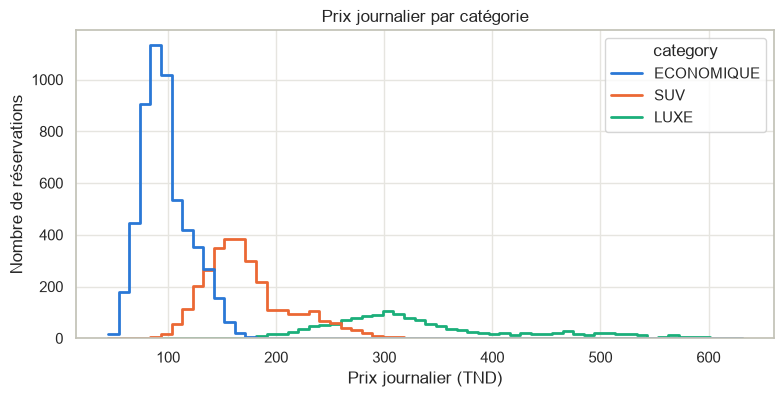

In [5]:
figure, axis = plt.subplots(figsize=(9, 4))
sns.histplot(data=feature_table, x="daily_price", hue="category", hue_order=CATEGORY_ORDER,
             palette=SERIES_COLORS, bins=60, element="step", fill=False, linewidth=2, ax=axis)
axis.set(title="Prix journalier par catégorie", xlabel="Prix journalier (TND)", ylabel="Nombre de réservations")
plt.show()

### 3.2 Prix selon la catégorie et la saison

Les boîtes montrent la médiane et la dispersion. Le prix monte de la basse à la haute saison,
et l'écart est plus fort pour le Luxe (été = saison des mariages).

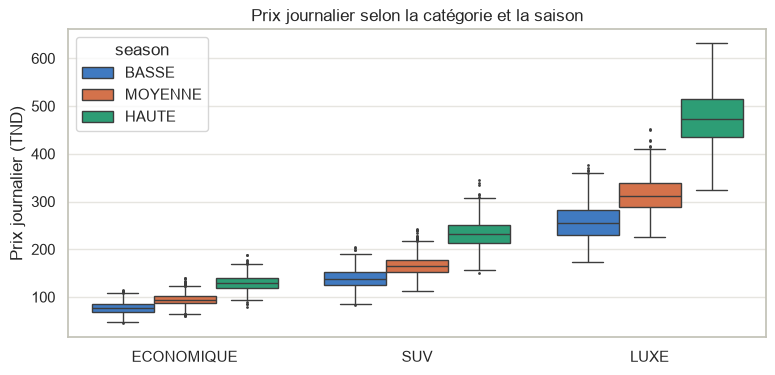

season,BASSE,MOYENNE,HAUTE
category,,,
ECONOMIQUE,77.4,94.1,129.6
SUV,138.2,165.7,233.2
LUXE,258.7,313.7,474.1


In [6]:
figure, axis = plt.subplots(figsize=(9, 4))
sns.boxplot(data=feature_table, x="category", y="daily_price", hue="season",
            order=CATEGORY_ORDER, hue_order=SEASON_ORDER, palette=SERIES_COLORS,
            fliersize=1, linewidth=1, ax=axis)
axis.set(title="Prix journalier selon la catégorie et la saison", xlabel="", ylabel="Prix journalier (TND)")
plt.show()

feature_table.pivot_table("daily_price", "category", "season").loc[CATEGORY_ORDER, SEASON_ORDER].round(1)

### 3.3 Taux d'occupation selon l'agence et la saison

La demande est différente entre les deux agences : Tunis reste stable toute l'année,
Sousse (station balnéaire) est presque vide en basse saison et presque pleine l'été.
C'est ce tableau que le service utilisera pour **estimer** l'occupation quand elle n'est pas fournie.

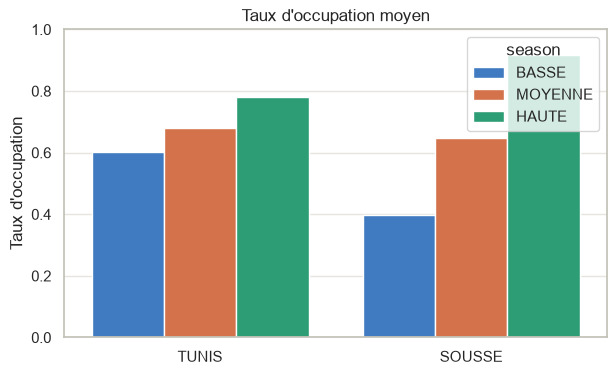

In [7]:
figure, axis = plt.subplots(figsize=(7, 4))
sns.barplot(data=feature_table, x="agency", y="occupancy_rate", hue="season", order=AGENCY_ORDER,
            hue_order=SEASON_ORDER, palette=SERIES_COLORS, errorbar=None, ax=axis)
axis.set(title="Taux d'occupation moyen", xlabel="", ylabel="Taux d'occupation", ylim=(0, 1))
plt.show()

### 3.4 Effet de la durée, du délai et du jour de départ

Pour comparer les catégories entre elles, on divise le prix par le tarif de base de la catégorie :
c'est l'**indice de prix** (1,0 = tarif de base). On regarde ensuite comment il varie.

On s'attend à voir des **paliers** (escaliers) et non des droites : c'est un indice que
la régression linéaire aura du mal.

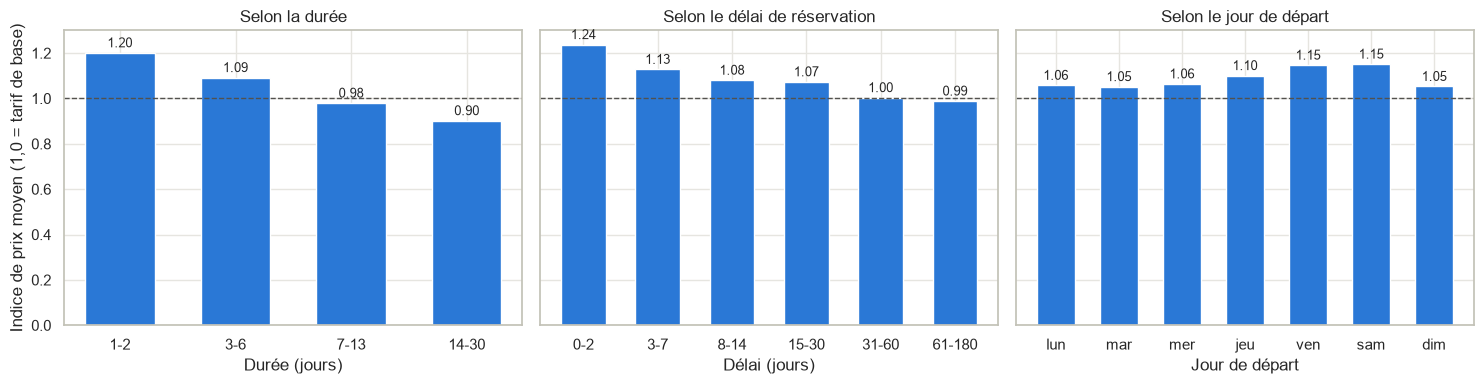

In [8]:
base_rate_by_code = {info["code"]: info["daily_rate"] for info in CATEGORIES.values()}
price_index = feature_table["daily_price"] / feature_table["category"].map(base_rate_by_code)
exploration_table = feature_table.assign(price_index=price_index)

duration_buckets = pd.cut(exploration_table["duration_days"], bins=[0, 2, 6, 13, 30],
                          labels=["1-2", "3-6", "7-13", "14-30"])
lead_time_buckets = pd.cut(exploration_table["lead_time_days"], bins=[-1, 2, 7, 14, 30, 60, 180],
                           labels=["0-2", "3-7", "8-14", "15-30", "31-60", "61-180"])
weekday_labels = exploration_table["start_weekday"].map(lambda day: WEEKDAY_NAMES[day])

charts = [
    ("Selon la durée", "Durée (jours)", duration_buckets, list(duration_buckets.cat.categories)),
    ("Selon le délai de réservation", "Délai (jours)", lead_time_buckets, list(lead_time_buckets.cat.categories)),
    ("Selon le jour de départ", "Jour de départ", weekday_labels, WEEKDAY_NAMES),
]
figure, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for axis, (title, x_label, grouping, group_order) in zip(axes, charts):
    mean_index = exploration_table.groupby(grouping, observed=True)["price_index"].mean().reindex(group_order)
    bars = axis.bar([str(label) for label in mean_index.index], mean_index.values, color=SERIES_COLORS[0], width=0.6)
    axis.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    axis.axhline(1.0, color="#52514e", linewidth=1, linestyle="--")
    axis.set(title=title, xlabel=x_label)
axes[0].set_ylabel("Indice de prix moyen (1,0 = tarif de base)")
plt.tight_layout()
plt.show()

**Ce qu'on retient de l'exploration**
- Pas de valeur manquante, des valeurs dans les limites prévues (durée 1–30 j, délai 0–180 j).
- La catégorie fixe le niveau de prix ; la saison, l'agence, l'occupation, le jour, la durée et le délai
  le **multiplient** (+/− x %).
- Les effets de la durée et du délai sont en **paliers**.

Conséquence : un modèle qui sait faire des « découpages » (arbres de décision : Random Forest, XGBoost)
devrait battre un modèle qui additionne des effets en ligne droite (régression linéaire).

## 4. Découper en trois jeux : entraînement, validation, test

| Jeu | Part | Sert à |
|---|---|---|
| **train** | 60 % | **entraîner** les 3 modèles |
| **validation** | 20 % | **choisir** le meilleur modèle et **calculer** les ratios de l'intervalle |
| **test** | 20 % | **mesure finale** uniquement : MAE, R², couverture de l'intervalle |

**Pourquoi trois jeux et pas deux ?** Chaque fois qu'on prend une décision en regardant un jeu de données
(choisir un modèle, régler l'intervalle), ce jeu n'est plus « neutre » : le résultat mesuré dessus est
trop optimiste. Exemple : si on calcule l'intervalle à 90 % sur un jeu et qu'on vérifie sa couverture
sur ce même jeu, on trouve 90 % **par construction**, sans rien apprendre.
Le test reste donc **enfermé** jusqu'à la fin : il joue le rôle de réservations futures que personne n'a vues.

`split_train_validation_test()` retire d'abord 20 % pour le test, puis coupe le reste en 75 % / 25 %
(soit 60 % / 20 % du total). La graine 42 rend le découpage reproductible.

In [9]:
data_splits = model_training.split_train_validation_test(feature_table)
train_features, train_prices = data_splits["train"]
validation_features, validation_prices = data_splits["validation"]
test_features, test_prices = data_splits["test"]

for split_name, (split_features, _) in data_splits.items():
    print(f"{split_name:<10} : {len(split_features)} réservations ({100 * len(split_features) / len(feature_table):.0f} %)")

train      : 6000 réservations (60 %)
validation : 2000 réservations (20 %)
test       : 2000 réservations (20 %)


## 5. Préparer les colonnes : `ColumnTransformer` dans un `Pipeline`

Un modèle ne comprend que des nombres. Le `ColumnTransformer` applique une préparation différente selon la colonne :
- **colonnes catégorielles** (catégorie, agence, saison, jour) → `OneHotEncoder` : une colonne 0/1 par valeur
  (ex. `season_HAUTE` = 1 si départ en haute saison). `handle_unknown="ignore"` évite une erreur si une valeur inconnue arrive ;
- **colonnes numériques** (durée, délai, occupation) → `StandardScaler` : mises à la même échelle
  (utile pour la régression linéaire, sans effet négatif pour les arbres).

Le `Pipeline` enchaîne **préparation + modèle** dans un seul objet. Avantages :
- `fit` apprend la préparation **uniquement sur le train** (pas de fuite d'information du test) ;
- l'API donnera directement les variables brutes au pipeline sauvegardé, sans risque d'oublier une étape.

In [10]:
example_pipeline = model_training.build_pipeline("LinearRegression")
example_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparation', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categories_to_columns', ...), ('numbers_scaled', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_thr

In [11]:
fitted_preprocessor = model_training.build_preprocessor().fit(train_features)
prepared_column_names = fitted_preprocessor.get_feature_names_out()
print(f"{len(train_features.columns)} variables -> {len(prepared_column_names)} colonnes après préparation :")
print(list(prepared_column_names))

7 variables -> 18 colonnes après préparation :
['categories_to_columns__category_ECONOMIQUE', 'categories_to_columns__category_LUXE', 'categories_to_columns__category_SUV', 'categories_to_columns__agency_SOUSSE', 'categories_to_columns__agency_TUNIS', 'categories_to_columns__season_BASSE', 'categories_to_columns__season_HAUTE', 'categories_to_columns__season_MOYENNE', 'categories_to_columns__start_weekday_0', 'categories_to_columns__start_weekday_1', 'categories_to_columns__start_weekday_2', 'categories_to_columns__start_weekday_3', 'categories_to_columns__start_weekday_4', 'categories_to_columns__start_weekday_5', 'categories_to_columns__start_weekday_6', 'numbers_scaled__duration_days', 'numbers_scaled__lead_time_days', 'numbers_scaled__occupancy_rate']


## 6. Entraîner les 3 modèles

| Modèle | Idée | Rôle ici |
|---|---|---|
| **LinearRegression** | prix = somme pondérée des colonnes | **référence** (baseline) : le minimum à battre |
| **RandomForest** | moyenne de 150 arbres de décision, chacun appris sur un échantillon différent | capte les paliers et les interactions |
| **XGBoost** | 500 petits arbres ajoutés un par un, chacun corrige les erreurs des précédents (boosting) | souvent le plus précis sur des données en tableau |

`train_model()` crée le pipeline du modèle demandé et l'entraîne sur le jeu d'entraînement.

In [12]:
import time

trained_pipelines = {}
for model_name in model_training.CANDIDATE_MODELS:
    start_time = time.perf_counter()
    trained_pipelines[model_name] = model_training.train_model(model_name, train_features, train_prices)
    print(f"{model_name:<17} entraîné en {time.perf_counter() - start_time:.1f} s")

LinearRegression  entraîné en 0.0 s


RandomForest      entraîné en 0.2 s


XGBoost           entraîné en 0.6 s


## 7. Comparer les modèles sur le jeu de **validation**

Deux métriques, calculées par `evaluate_model()` :
- **MAE** (erreur absolue moyenne) : en moyenne, de combien de TND la prédiction se trompe. **Plus petit = mieux.**
- **R²** (coefficient de détermination) : part de la variation des prix que le modèle explique.
  1 = parfait, 0 = pas mieux que prédire toujours la moyenne. **Plus grand = mieux.**

On ajoute la MAE en % du prix moyen pour la lire plus facilement.
La comparaison se fait sur la **validation** : le test n'est pas encore utilisé.

In [13]:
average_validation_price = validation_prices.mean()
comparison_rows = []
for model_name, pipeline in trained_pipelines.items():
    validation_metrics = model_training.evaluate_model(pipeline, validation_features, validation_prices)
    comparison_rows.append({
        "modèle": model_name,
        "MAE validation (TND)": validation_metrics["mae"],
        "MAE (% du prix moyen)": round(100 * validation_metrics["mae"] / average_validation_price, 1),
        "R² validation": validation_metrics["r2"],
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("modèle").sort_values("MAE validation (TND)")
print(f"Prix moyen du jeu de validation : {average_validation_price:.1f} TND")
model_comparison

Prix moyen du jeu de validation : 154.9 TND


,MAE validation (TND),MAE (% du prix moyen),R² validation
modèle,,,
XGBoost,6.934,4.5,0.988
RandomForest,8.325,5.4,0.982
LinearRegression,16.499,10.7,0.924


### Visualiser la comparaison (validation)

À gauche : la MAE de chaque modèle. À droite : prix réel en fonction du prix prédit pour chaque modèle ;
plus les points sont collés à la diagonale, meilleures sont les prédictions.

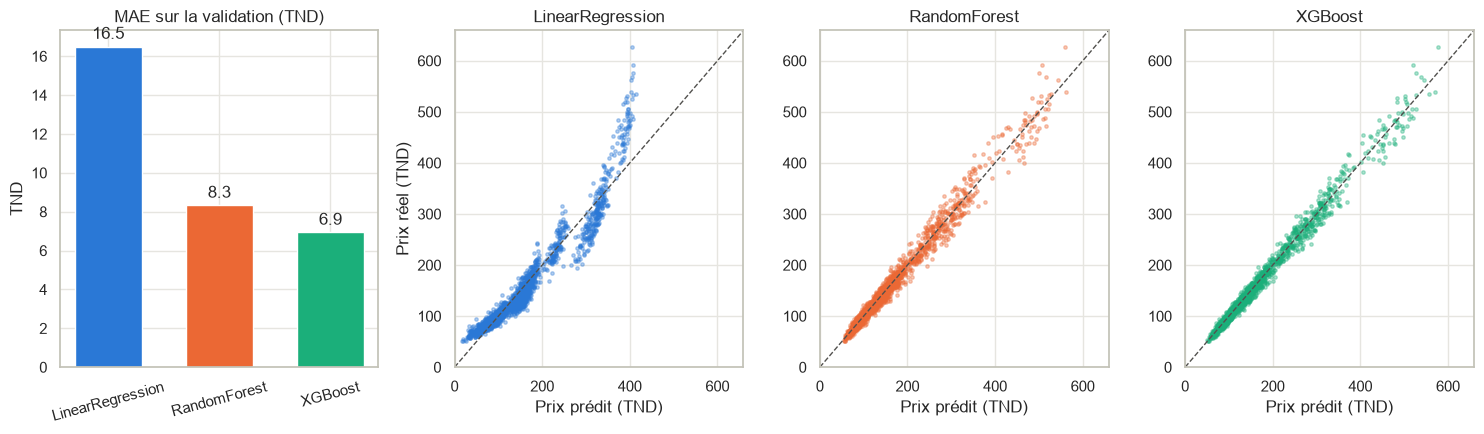

In [14]:
model_names = list(model_training.CANDIDATE_MODELS)
figure = plt.figure(figsize=(15, 4.5))
grid = figure.add_gridspec(1, 4, width_ratios=[1.1, 1, 1, 1])

mae_axis = figure.add_subplot(grid[0])
mae_values = [model_comparison.loc[name, "MAE validation (TND)"] for name in model_names]
bars = mae_axis.bar(model_names, mae_values, color=SERIES_COLORS, width=0.6)
mae_axis.bar_label(bars, fmt="%.1f", padding=3)
mae_axis.set(title="MAE sur la validation (TND)", ylabel="TND")
mae_axis.tick_params(axis="x", rotation=15)

for position, model_name in enumerate(model_names, start=1):
    scatter_axis = figure.add_subplot(grid[position])
    predicted_prices = trained_pipelines[model_name].predict(validation_features)
    scatter_axis.scatter(predicted_prices, validation_prices, s=6, alpha=0.35, color=SERIES_COLORS[position - 1])
    price_limits = [0, max(validation_prices.max(), predicted_prices.max()) * 1.05]
    scatter_axis.plot(price_limits, price_limits, color="#52514e", linewidth=1, linestyle="--")
    scatter_axis.set(title=model_name, xlabel="Prix prédit (TND)", ylabel="Prix réel (TND)" if position == 1 else "",
                     xlim=price_limits, ylim=price_limits)
plt.tight_layout()
plt.show()

## 8. Choisir le meilleur modèle

On retient le modèle qui a la **plus petite MAE sur la validation** (erreur moyenne en TND la plus faible).

In [15]:
best_model_name = model_comparison["MAE validation (TND)"].idxmin()
best_pipeline = trained_pipelines[best_model_name]
print(f"Modèle choisi sur la validation : {best_model_name}")

Modèle choisi sur la validation : XGBoost


## 9. Intervalle de prix (calculé sur la validation)

Un prix seul ne dit pas à quel point on peut s'y fier. On fournit donc un **intervalle**.

Méthode (`compute_interval_ratios()`) : sur le jeu de **validation**, on calcule pour chaque réservation
le **ratio** `prix réel / prix prédit` (ex. 1,05 = le vrai prix était 5 % au-dessus).
On prend les quantiles **5 %** et **95 %** de ces ratios. Pour une nouvelle prédiction :

`lowerBound = prix prédit × ratio_bas` et `upperBound = prix prédit × ratio_haut`.

Pourquoi un ratio et pas une erreur en TND ? Une erreur de 15 TND est grosse pour une Économique à 90 TND
mais petite pour un Luxe à 450 TND : en pourcentage, l'intervalle s'adapte à chaque catégorie.

In [16]:
interval_ratios = model_training.compute_interval_ratios(best_pipeline, validation_features, validation_prices)
print(f"Ratios : bas = {interval_ratios['lower_ratio']}, haut = {interval_ratios['upper_ratio']}")
print(f"=> intervalle de {100 * (interval_ratios['lower_ratio'] - 1):+.1f} % à {100 * (interval_ratios['upper_ratio'] - 1):+.1f} % autour du prix prédit")

Ratios : bas = 0.9102, haut = 1.0881
=> intervalle de -9.0 % à +8.8 % autour du prix prédit


## 10. Mesure finale sur le jeu de test

Toutes les décisions sont prises (modèle choisi, intervalle calculé). On ouvre enfin le **test**,
une seule fois, pour mesurer honnêtement le modèle retenu :
- **MAE** et **R²** sur des réservations jamais utilisées pour une décision ;
- **couverture** de l'intervalle : part des prix réels du test qui tombent dedans (`measure_interval_coverage()`).
  Cette fois, 90 % n'est **pas** garanti : si on s'en approche, c'est que l'intervalle est fiable.

On compare avec les chiffres de validation : s'ils sont proches, il n'y a pas de sur-ajustement.

In [17]:
validation_metrics = model_training.evaluate_model(best_pipeline, validation_features, validation_prices)
test_metrics = model_training.evaluate_model(best_pipeline, test_features, test_prices)
validation_coverage = model_training.measure_interval_coverage(best_pipeline, interval_ratios, validation_features, validation_prices)
test_coverage = model_training.measure_interval_coverage(best_pipeline, interval_ratios, test_features, test_prices)

final_measures = pd.DataFrame({
    "validation (décisions)": [validation_metrics["mae"], validation_metrics["r2"], f"{100 * validation_coverage:.1f} % (par construction)"],
    "test (mesure finale)": [test_metrics["mae"], test_metrics["r2"], f"{100 * test_coverage:.1f} %"],
}, index=["MAE (TND)", "R²", "couverture de l'intervalle"])
print(f"Modèle retenu : {best_model_name}")
final_measures

Modèle retenu : XGBoost


,validation (décisions),test (mesure finale)
MAE (TND),6.934,6.728
R²,0.988,0.988
couverture de l'intervalle,90.0 % (par construction),90.8 %


## 11. Tableau d'occupation (estimation par défaut)

L'API reçoit seulement catégorie, agence et dates ; le champ `occupancyRate` est **optionnel**.
S'il manque, on utilise la **moyenne historique** pour l'agence et la saison du départ,
calculée ici sur le jeu d'entraînement par `compute_occupancy_table()`.

In [18]:
occupancy_table = model_training.compute_occupancy_table(train_features)
pd.DataFrame(occupancy_table).T.loc[AGENCY_ORDER, SEASON_ORDER]

,BASSE,MOYENNE,HAUTE
TUNIS,0.600,0.679,0.784
SOUSSE,0.397,0.649,0.916


## 12. Essai : ce que fera l'API

Exemple : un **SUV à Sousse**, départ le vendredi 2026-07-17, retour le 2026-07-21 (4 jours),
réservé le 2026-06-20 (27 jours avant), occupation non fournie → estimée (Sousse, haute saison).

On utilise `build_features()` (le calcul de l'API), puis le pipeline et les ratios de l'intervalle.

In [19]:
example_start, example_end, example_booked_on = date(2026, 7, 17), date(2026, 7, 21), date(2026, 6, 20)
estimated_occupancy = occupancy_table["SOUSSE"]["HAUTE"]
example_features = build_features(CATEGORY_ID_BY_CODE["SUV"], AGENCY_ID_BY_CODE["SOUSSE"],
                                  example_start, example_end, example_booked_on, estimated_occupancy)
print("Variables calculées :", example_features)

example_price = float(best_pipeline.predict(pd.DataFrame([example_features]))[0])
print(f"Prix journalier conseillé : {example_price:.3f} TND")
print(f"Intervalle               : {example_price * interval_ratios['lower_ratio']:.3f} – {example_price * interval_ratios['upper_ratio']:.3f} TND")

Variables calculées : {'category': 'SUV', 'agency': 'SOUSSE', 'season': 'HAUTE', 'start_weekday': 4, 'duration_days': 4, 'lead_time_days': 27, 'occupancy_rate': 0.916}
Prix journalier conseillé : 251.629 TND
Intervalle               : 229.033 – 273.798 TND


## 13. Sauvegarder le modèle (version 1)

`create_model_bundle()` regroupe dans **un seul objet** tout ce dont l'API a besoin :
le pipeline entraîné, le nom du modèle, la version, les métriques **mesurées sur le test**
(MAE, R², couverture), les ratios de l'intervalle,
le tableau d'occupation, la liste des colonnes et la date d'entraînement.

`save_model_bundle()` l'écrit avec **joblib** (format de sauvegarde des objets Python, compressé)
dans `artifacts/price_model_v1.joblib`. On le recharge ensuite pour vérifier qu'il donne la même prédiction.

In [20]:
model_bundle = model_artifacts.create_model_bundle(
    model_name=best_model_name, version=1, pipeline=best_pipeline,
    metrics={**test_metrics, "interval_coverage": test_coverage, "validation_mae": validation_metrics["mae"]},
    interval_ratios=interval_ratios, occupancy_table=occupancy_table, training_rows=len(train_features))
saved_file_path = model_artifacts.save_model_bundle(model_bundle)
print(f"Sauvegardé : {saved_file_path.name} ({saved_file_path.stat().st_size / 1024:.0f} Ko)")

reloaded_bundle = model_artifacts.load_model_bundle(version=1)
reloaded_price = float(reloaded_bundle["pipeline"].predict(pd.DataFrame([example_features]))[0])
print(f"Prix avec le modèle rechargé : {reloaded_price:.3f} TND (identique : {abs(reloaded_price - example_price) < 1e-9})")
print({key: value for key, value in reloaded_bundle.items() if key != "pipeline"})

Sauvegardé : price_model_v1.joblib (353 Ko)
Prix avec le modèle rechargé : 251.629 TND (identique : True)
{'model_name': 'XGBoost', 'version': 1, 'metrics': {'mae': 6.728, 'r2': 0.9875, 'interval_coverage': 0.9075, 'validation_mae': 6.934}, 'interval_ratios': {'lower_ratio': 0.9102, 'upper_ratio': 1.0881, 'confidence': 0.9}, 'occupancy_table': {'SOUSSE': {'BASSE': 0.397, 'HAUTE': 0.916, 'MOYENNE': 0.649}, 'TUNIS': {'BASSE': 0.6, 'HAUTE': 0.784, 'MOYENNE': 0.679}}, 'feature_columns': ['category', 'agency', 'season', 'start_weekday', 'duration_days', 'lead_time_days', 'occupancy_rate'], 'training_rows': 6000, 'trained_at': '2026-11-09T18:40:09Z'}


## 14. Conclusion

**Choix (sur la validation, 2 000 réservations)** : **XGBoost** est retenu (version 1).

| Modèle | MAE validation | R² validation |
|---|---|---|
| XGBoost | 6,9 TND (4,5 % du prix moyen) | 0,988 |
| Random Forest | 8,3 TND (5,4 %) | 0,982 |
| Régression linéaire (référence) | 16,5 TND (10,7 %) | 0,924 |

**Mesure finale (sur le test, jamais utilisé avant)** : MAE **6,7 TND**, R² **0,988**,
et **90,8 %** des prix réels tombent dans l'intervalle (objectif 90 %).
Les chiffres du test sont aussi bons que ceux de la validation : le modèle n'est pas sur-ajusté
et l'intervalle est fiable sur des réservations qu'il n'avait jamais vues.

**Pourquoi les arbres battent la régression linéaire**
- **Règles multiplicatives** : dans nos données, la saison, l'agence, l'occupation, etc. *multiplient* le prix.
  +25 % en haute saison, c'est +22 TND pour une Économique mais +75 TND pour un Luxe.
  La régression linéaire, elle, *ajoute* un montant fixe par colonne, le même pour toutes les catégories :
  elle surestime les petits prix et sous-estime les grands. On le voit à la **courbe en banane**
  de son graphique « réel / prédit ».
- **Paliers** : la durée et le délai agissent par seuils (1–2 j, 3–6 j, 7–13 j…). Une droite ne peut pas
  suivre un escalier ; un arbre de décision, lui, découpe justement les valeurs en intervalles
  (« si durée ≤ 2 et catégorie = LUXE alors… ») et combine les conditions.
- **XGBoost devant Random Forest** : Random Forest fait la *moyenne* d'arbres indépendants, ce qui lisse un peu les paliers ;
  XGBoost ajoute des arbres *un par un*, chacun corrigeant les erreurs restantes des précédents.

**Proche du maximum possible** : le générateur ajoute un bruit aléatoire d'environ ±5 % que personne ne peut prédire.
Ce bruit seul donne une MAE minimale d'environ 0,8 × 5 % × 155 TND ≈ **6,2 TND**.
Avec 6,7 TND sur le test, XGBoost a appris presque tout ce qui était apprenable.

**Méthode** : trois jeux séparés. Le modèle est choisi et l'intervalle est calculé sur la **validation** ;
le **test** ne sert qu'à la mesure finale. Sans cette séparation, la couverture de 90 % aurait été
garantie par construction et n'aurait rien prouvé.

**Limites**
- **Données synthétiques** : le modèle retrouve des règles que nous avons écrites nous-mêmes.
  Ses performances réelles ne seront connues qu'avec de vraies réservations
  (plus tard, via les événements `ReservationCompleted` de RabbitMQ).
- **Modèle entraîné sur 60 % des données** seulement : le réentraîner sur train + validation
  utiliserait plus de données, mais il faudrait alors une autre façon de calculer l'intervalle.
- **Intervalle identique pour tous les cas** (même pourcentage), alors que certains cas rares
  (longues durées, Luxe en été) sont sans doute plus incertains.
- **Découpage aléatoire** et non chronologique : en production, on prédit le futur à partir du passé.
  Un test « entraîner sur 2023–2024, tester sur 2025 » serait plus exigeant.
- **Hyperparamètres choisis à la main**, sans validation croisée ni recherche (`GridSearchCV`).
- **Occupation estimée** par une moyenne agence × saison : elle ignore l'état réel du parc au jour de la demande.
- **Calendrier simplifié** : la saison dépend seulement du mois (ramadan, Aïd et vacances scolaires non modélisés).
- **Catalogue figé** : une nouvelle catégorie ou agence demandera de régénérer les données et de réentraîner ;
  d'ici là, l'API la refusera (422).

**Pistes d'amélioration** : prédire le logarithme du prix (ce qui rendrait les effets additifs et aiderait
la régression linéaire), validation croisée et réglage des hyperparamètres, découpage chronologique,
intervalle par catégorie.